# Extended Data Figure 5G — eIF5 N30 hydrogen-bond partners

Circle (nested pie) plots of N30 H-bond partner fractions, clones aggregated per system.

Data: `../data/hbond-residue/`

In [1]:
from pathlib import Path
FIG_DIR = Path('figures'); FIG_DIR.mkdir(exist_ok=True)
TABLE_DIR = Path('tables'); TABLE_DIR.mkdir(exist_ok=True)

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import re
from typing import Dict, List, Tuple
from collections import defaultdict

## Configuration

In [3]:
# Residue grouping by dataset
RESIDUE_GROUPS = {
    '20250917': {
        'eIF5': [986, 987, 989, 990],
        'tRNAi': list(range(2053, 2057)),  # 2053-2056
        'mRNA': list(range(2102, 2105)),   # 2102-2104
        'rRNA': [2567, 2568]
    },
    '20251112': {
        'eIF5': [844, 845, 847, 848, 849],
        'tRNAi': [1911, 1912, 1913, 1914],
        'mRNA': [1960, 1961, 1962],
        'rRNA': [2425, 2426]
    }
}

# Color scheme for groups
GROUP_COLORS = {
    'eIF5': '#8d2788',      # Purple
    'tRNAi': '#28b24b',     # Green
    'mRNA': '#f38fbb',      # Pink
    'rRNA': '#4a95d0',      # Blue
    'tRNA+mRNA': '#FFD700', # Gold - for bridging H-bonds spanning both tRNA and mRNA
    'No H-bond': '#bcbec0'  # Gray
}

In [4]:
# Per-residue colors for 20251112 dataset (placeholder hex codes - fill in later)
RESIDUE_COLORS = {
    # eIF5 (residues 844-849)
    'LYS_844': '#662d91',
    'ALA_845': '#662d91',
    'GLY_845': '#662d91',  # N30K variant
    'ALA_847': '#662d91',
    'GLY_847': '#662d91',  # N30K variant
    'ALA_848': '#662d91',
    'ALA_849': '#662d91',
    # tRNAi (residues 1911-1914)
    'A_1911': '#000000', #Not used??
    'U_1912': '#c8e5cc',
    'A_1913': '#84ca98',
    'A_1914': '#64bf77',
    # # mRNA (residues 1960-1962) salmon
    # 'U_1960': '#f58873',
    # 'C_1960': '#f58873',
    # 'A_1960': '#f58873',
    # 'U_1961': '#f69f8f',
    # 'C_1961': '#f69f8f',
    # 'G_1962': '#fbc9bf',
    # mRNA (residues 1960-1962) pink
    'U_1960': '#f3d5e6',
    'C_1960': '#f3d5e6',
    'A_1960': '#f3d5e6',
    'U_1961': '#d77cb2',
    'C_1961': '#d77cb2',
    'G_1962': '#000000', ## Not used??
    
    # rRNA (residues 2425-2426)
    'C_2425': '#b5daf4',
    'G_2426': '#74a7cf',
    # Special categories
    'Two H-bonds': '#ffdd8f',       # Gold
    'Three+ H-bonds': '#FFA500',    # Orange (3 or more)
    'No H-bond': '#bcbec0',         # Gray
}

# Display labels for residues (maps internal names to readable labels)
RESIDUE_LABELS = {
    # tRNAi anticodon positions
    'U_1912': 'U35',
    'A_1913': 'A36',
    'A_1914': 'A37',
    # mRNA codon positions (+1, +2, +3 relative to start)
    'U_1960': '+1',
    'C_1960': '+1',
    'A_1960': '+1',
    'G_1960': '+1',
    'U_1961': '+2',
    'C_1961': '+2',
    'G_1962': '+3',
}

In [5]:
# Data directory
DATA_DIR = Path('../data/hbond-residue')

# Analysis parameters
TIME_STEP = 0.1  # ns per frame
ANALYSIS_START_FRAME = 13000  # Start of production analysis window
ANALYSIS_END_FRAME = 23000    # End of production analysis window

## Parsing functions

In [6]:
def parse_filename(filename: str) -> Dict[str, str]:
    """
    Parse filename to extract system information and stores it in a dictionary.
    
    Example: 20250917_48S_eIF5wt_AUG_clone0-HB_N30-matrix_residue.dat will return

    {'date': '20250917',
     'variant': 'eIF5wt',
     'codon': 'AUG',
     'clone': '0',
     'system': '20250917_eIF5wt_AUG'}

    """
    pattern = r'(\d{8})_48S_(eIF5.*?)_(AUG|ACG|CUG|UUG|AUC|GUG)_clone(\d+)-HB_N30-matrix_residue\.dat'
    match = re.match(pattern, filename)
    
    if match:
        return {
            'date': match.group(1),
            'variant': match.group(2),
            'codon': match.group(3),
            'clone': match.group(4),
            'system': f"{match.group(1)}_{match.group(2)}_{match.group(3)}"
        }
    return None

In [7]:
def get_residue_group(residue_name: str, date: str) -> str:
    """
    Map a residue name to its structural group.
    
    Args:
        residue_name: e.g., 'U_2054', 'GLY_987', 'A_2102'
        date: Dataset identifier ('20250917' or '20251112')
    
    Returns:
        Group name ('eIF5', 'tRNAi', 'mRNA', 'rRNA', or 'Unknown')
    """
    # Extract residue number
    match = re.search(r'_(\d+)$', residue_name)
    if not match:
        return 'Unknown'
    
    res_num = int(match.group(1))
    
    # Check which group this residue belongs to
    groups = RESIDUE_GROUPS.get(date, {})
    for group_name, residue_list in groups.items():
        if res_num in residue_list:
            return group_name
    
    return 'Unknown'

In [8]:
def load_residue_matrix(filepath: Path) -> Tuple[np.ndarray, List[str], Dict]:
    """
    Load a residue-level H-bond matrix file.
    
    Returns:
        matrix: 2D array (frames x residues) of H-bond counts
        residue_names: List of residue names
        info: Parsed filename information
    """
    # Parse filename
    info = parse_filename(filepath.name)
    if info is None:
        raise ValueError(f"Could not parse filename: {filepath.name}")
    
    # Read header to get residue names
    with open(filepath, 'r') as f:
        header = f.readline().strip()
    
    residue_names = header.split()[1:]  # Skip '#Frame'
    
    # Load data
    data = np.loadtxt(filepath, skiprows=1)
    
    # Extract matrix (skip frame column)
    matrix = data[:, 1:].astype(int)
    
    return matrix, residue_names, info

In [9]:
def aggregate_clones(file_paths: List[Path],
                     start_frame: int = ANALYSIS_START_FRAME,
                     end_frame: int = ANALYSIS_END_FRAME) -> Tuple[np.ndarray, List[str], str]:
    """
    Aggregate multiple clone files into a single combined matrix.

    Handles cases where different clones have different sets of residues by creating
    a unified residue set and padding missing residues with zeros.

    IMPORTANT: Applies frame window to each clone individually before aggregation.

    Args:
        file_paths: List of paths to matrix files for different clones
        start_frame: Start of analysis window (applied per clone)
        end_frame: End of analysis window (applied per clone)

    Returns:
        combined_matrix: Concatenated matrix from all clones (after frame windowing)
        residue_names: Sorted list of all unique residue names across clones
        date: Dataset identifier
    """
    # First pass: collect all unique residues and load all data
    all_residues = set()
    clone_data = []
    date = None

    for filepath in file_paths:
        matrix, res_names, info = load_residue_matrix(filepath)
        clone_data.append({
            'matrix': matrix,
            'residues': res_names,
            'filepath': filepath
        })
        all_residues.update(res_names)

        if date is None:
            date = info['date']

    # Create sorted unified residue list
    unified_residues = sorted(all_residues)
    residue_to_idx = {res: idx for idx, res in enumerate(unified_residues)}

    print(f"  Found {len(unified_residues)} unique residues across {len(file_paths)} clones")

    # Second pass: create standardized matrices with frame windowing
    standardized_matrices = []

    for clone_info in clone_data:
        original_matrix = clone_info['matrix']
        original_residues = clone_info['residues']

        # Apply frame window to this clone
        matrix_windowed = original_matrix[start_frame:end_frame, :]
        n_frames = matrix_windowed.shape[0]

        # Create new matrix with all residues (initialized to zeros)
        standardized_matrix = np.zeros((n_frames, len(unified_residues)), dtype=int)

        # Fill in data for residues that exist in this clone
        for orig_idx, res_name in enumerate(original_residues):
            unified_idx = residue_to_idx[res_name]
            standardized_matrix[:, unified_idx] = matrix_windowed[:, orig_idx]

        standardized_matrices.append(standardized_matrix)

    # Concatenate along frame axis
    combined_matrix = np.vstack(standardized_matrices)

    return combined_matrix, unified_residues, date

In [10]:
def calculate_hbond_fractions(matrix: np.ndarray,
                              residue_names: List[str],
                              date: str = '20251112') -> Tuple[Dict[str, float], Dict[str, float], Dict[str, Dict[str, float]]]:
    """
    Calculate the fraction of frames assigned to each category using mutually exclusive assignment.

    For each frame:
    - If H-bond with exactly one residue -> assign to that residue
    - If H-bonds with multiple residues on the SAME domain -> assign as a same-domain combination
      (NOT added to individual residue counts - gets its own wedge with hatching)
    - If H-bonds span BOTH tRNAi AND mRNA -> assign to "tRNA+mRNA" bridging category
    - If no H-bonds -> assign to "No H-bond"

    Args:
        matrix: H-bond matrix (frames x residues) - should already be windowed
        residue_names: List of residue names
        date: Dataset identifier for residue grouping

    Returns:
        Tuple of:
        - Dictionary mapping residue/category names to fraction of frames
        - Dictionary mapping combination strings to fractions (for tRNA+mRNA bridging frames)
        - Dictionary mapping domain -> {combo_string: fraction} for same-domain multiples
    """
    n_frames = matrix.shape[0]

    # Initialize counters - only for single H-bond frames
    residue_counts = {res: 0 for res in residue_names}
    tRNA_mRNA_count = 0
    no_hbond_count = 0

    # Track combinations for tRNA+mRNA bridging frames
    bridging_combination_counts: Dict[str, int] = defaultdict(int)

    # Track same-domain multiple H-bond combinations
    # Structure: domain -> {combo_string: count}
    same_domain_multiples: Dict[str, Dict[str, int]] = defaultdict(lambda: defaultdict(int))

    # Process each frame
    for frame_idx in range(n_frames):
        frame_data = matrix[frame_idx, :]

        # Find which residues have H-bonds in this frame
        bonded_residues = [residue_names[i] for i in range(len(residue_names))
                          if frame_data[i] > 0]

        # Assign frame to category
        if len(bonded_residues) == 0:
            no_hbond_count += 1
        elif len(bonded_residues) == 1:
            # Single H-bond - count toward individual residue
            residue_counts[bonded_residues[0]] += 1
        else:
            # Multiple H-bonds - determine which domains are involved
            domains_involved = set()
            residues_by_domain: Dict[str, List[str]] = defaultdict(list)

            for res in bonded_residues:
                domain = get_residue_group(res, date)
                domains_involved.add(domain)
                residues_by_domain[domain].append(res)

            # Check if this is a tRNA+mRNA bridging frame
            has_tRNAi = 'tRNAi' in domains_involved
            has_mRNA = 'mRNA' in domains_involved

            if has_tRNAi and has_mRNA:
                # This is a bridging frame (tRNA+mRNA)
                tRNA_mRNA_count += 1
                combo_key = " + ".join(sorted(bonded_residues))
                bridging_combination_counts[combo_key] += 1
            elif len(domains_involved) == 1:
                # All bonds on same domain - count as combination, NOT individual residues
                domain = list(domains_involved)[0]
                combo_key = " + ".join(sorted(bonded_residues))
                same_domain_multiples[domain][combo_key] += 1
            else:
                # Multiple domains but not tRNA+mRNA bridging (e.g., eIF5+rRNA)
                # Treat as same-domain multiples for each domain involved
                for domain, res_list in residues_by_domain.items():
                    if len(res_list) == 1:
                        # Single residue from this domain - count individually
                        residue_counts[res_list[0]] += 1
                    else:
                        # Multiple residues from this domain - count as combination
                        combo_key = " + ".join(sorted(res_list))
                        same_domain_multiples[domain][combo_key] += 1

    # Convert ALL counts to fractions
    residue_fractions = {res: count / n_frames for res, count in residue_counts.items()}
    residue_fractions['tRNA+mRNA'] = tRNA_mRNA_count / n_frames
    residue_fractions['No H-bond'] = no_hbond_count / n_frames

    # Convert bridging_combination_counts to fractions
    bridging_fractions = {combo: count / n_frames for combo, count in bridging_combination_counts.items()}

    # Convert same_domain_multiples to fractions
    same_domain_fractions = {}
    for domain, combos in same_domain_multiples.items():
        same_domain_fractions[domain] = {combo: count / n_frames for combo, count in combos.items()}

    return residue_fractions, bridging_fractions, same_domain_fractions

## Visualization Functions

In [11]:
def plot_hbond_pie_chart_by_residue(residue_fractions: Dict[str, float],
                                     date: str,
                                     title: str,
                                     ax=None) -> None:
    """
    Create pie chart with segments ordered by residue number.
    Uses RESIDUE_COLORS for coloring.
    
    The chart is centered so the tRNAi/mRNA boundary is at 12 o'clock position.
    
    Args:
        residue_fractions: Dictionary mapping residue names to fractions
        date: Dataset identifier for residue grouping
        title: Plot title
        ax: Matplotlib axis (optional)
    """
    if ax is None:
        fig, ax = plt.subplots(figsize=(10, 10))

    # Filter out residues with zero fraction (except special categories)
    filtered = {k: v for k, v in residue_fractions.items() 
                if v > 0.001 or k in ['Two H-bonds', 'Three+ H-bonds', 'No H-bond']}

    if not filtered or (len(filtered) == 1 and 'No H-bond' in filtered):
        ax.text(0.5, 0.5, 'No H-bonds detected',
                ha='center', va='center', fontsize=14)
        ax.set_title(title, fontsize=14, fontweight='bold', pad=20)
        return

    # Sort by residue number (extract number from name like 'A_1912' -> 1912)
    def get_sort_key(name: str) -> Tuple[int, int]:
        if name in ['Two H-bonds', 'Three+ H-bonds', 'No H-bond']:
            # Put special categories at end, in this order
            return (1, ['Two H-bonds', 'Three+ H-bonds', 'No H-bond'].index(name))
        match = re.search(r'_(\d+)$', name)
        return (0, int(match.group(1)) if match else 0)

    sorted_names = sorted(filtered.keys(), key=get_sort_key)

    # Build lists in sorted order
    labels = sorted_names
    sizes = [filtered[name] for name in sorted_names]
    colors = [RESIDUE_COLORS.get(name, '#888888') for name in sorted_names]

    # Calculate startangle to center tRNAi/mRNA boundary at 12 o'clock
    # Find cumulative fraction up to and including last tRNAi residue
    total = sum(sizes)
    cumulative = 0
    for i, name in enumerate(sorted_names):
        group = get_residue_group(name, date) if name not in ['Two H-bonds', 'Three+ H-bonds', 'No H-bond'] else 'Special'
        cumulative += sizes[i]
        # Check if next residue is mRNA (or this is last tRNAi)
        if group == 'tRNAi':
            next_idx = i + 1
            if next_idx < len(sorted_names):
                next_name = sorted_names[next_idx]
                next_group = get_residue_group(next_name, date) if next_name not in ['Two H-bonds', 'Three+ H-bonds', 'No H-bond'] else 'Special'
                if next_group != 'tRNAi':
                    # This is the last tRNAi residue
                    break
    
    # startangle: pie chart starts at this angle, going counter-clockwise
    # We want the boundary after tRNAi (cumulative fraction) to be at 90° (12 o'clock)
    # So startangle = 90 - (cumulative/total * 360)
    startangle = 90 - (cumulative / total * 360)

    # Create explode effect (slightly separate all wedges)
    explode = tuple([0.00] * len(sizes))
    
    # Create pie chart (NOT sorted by size - keep residue number order)
    wedges, texts, autotexts = ax.pie(
        sizes,
        labels=labels,
        colors=colors,
        autopct=lambda pct: f'{pct:.1f}%' if pct > 2 else '',
        pctdistance=0.75,
        startangle=startangle,
        explode=explode,
        textprops={'fontsize': 9, 'weight': 'bold'}
    )

    # Make percentage text more readable
    for autotext in autotexts:
        autotext.set_color('white')
        autotext.set_fontsize(9)

    # Adjust label positions for better readability
    for text in texts:
        text.set_fontsize(8)

    # Create center circle for donut effect
    centre_circle = plt.Circle((0, 0), 0.50, fc='white')
    ax.add_artist(centre_circle)

    ax.set_title(title, fontsize=14, fontweight='bold', pad=20)

In [12]:
def get_display_label(residue_name: str) -> str:
    """
    Get the display label for a residue name.
    Uses RESIDUE_LABELS if available, otherwise returns the original name.
    """
    return RESIDUE_LABELS.get(residue_name, residue_name)


def plot_nested_hbond_pie_chart(residue_fractions: Dict[str, float],
                                 date: str,
                                 title: str,
                                 bridging_fractions: Dict[str, float] = None,
                                 same_domain_fractions: Dict[str, Dict[str, float]] = None,
                                 codon: str = None,
                                 hatch_linewidth: float = 2.0,
                                 hatch_pattern: str = '/',
                                 show_hatches: bool = True,
                                 hatch_alpha: float = 1.0,
                                 ax=None) -> None:
    """
    Create nested pie chart with outer ring showing domain groups and inner ring showing residues.

    Outer ring: Domain groups (eIF5, tRNAi, mRNA, rRNA, tRNA+mRNA bridging, No H-bond)
    Inner ring: Individual residues + same-domain multiple combinations (with hatching)
                - Single H-bond residues: no hatching
                - Same-domain multiple combinations: separate wedge with hatching
                - tRNA+mRNA bridging combinations: separate wedges with hatching

    Args:
        residue_fractions: Dictionary mapping residue names to fractions (single H-bond frames)
        date: Dataset identifier for residue grouping
        title: Plot title
        bridging_fractions: Dict mapping combination strings to fractions (tRNA+mRNA bridging)
        same_domain_fractions: Dict mapping domain -> {combo_string: fraction} for same-domain multiples
        codon: Codon type (e.g., 'UUG') to determine number of top combinations to show
        hatch_linewidth: Line width for hatch patterns
        hatch_pattern: Hatch pattern string
        show_hatches: Whether to show hatch patterns
        hatch_alpha: Alpha for hatched segment face colors
        ax: Matplotlib axis (optional, must be polar projection)
    """
    plt.rcParams['hatch.linewidth'] = hatch_linewidth

    if ax is None:
        fig, ax = plt.subplots(subplot_kw=dict(projection="polar"), figsize=(10, 10))

    # Define group order
    group_order = ['eIF5', 'tRNAi', 'mRNA', 'rRNA', 'tRNA+mRNA', 'No H-bond']

    # Determine number of top combinations to show (3 for UUG, 2 for others)
    n_top_combos = 3 if codon == 'UUG' else 2

    # Build outer (groups) and inner (residues) data
    outer_labels = []
    outer_sizes = []
    outer_colors = []
    outer_hatches = []
    outer_hatch_colors = []

    inner_labels = []
    inner_sizes = []
    inner_colors = []
    inner_hatches = []
    inner_hatch_colors = []

    for group in group_order:
        group_inner_items = []

        if group == 'tRNA+mRNA':
            # Handle tRNA+mRNA bridging category
            bridging_total = residue_fractions.get('tRNA+mRNA', 0)
            if bridging_total <= 0.001:
                continue

            # Get top bridging combinations
            if bridging_fractions:
                sorted_combos = sorted(bridging_fractions.items(), key=lambda x: -x[1])
                top_combos = sorted_combos[:n_top_combos]
                other_frac = sum(f for _, f in sorted_combos[n_top_combos:])

                for combo_str, frac in top_combos:
                    residues = [r.strip() for r in combo_str.split(" + ")]
                    if len(residues) >= 2 and show_hatches:
                        res_colors = [RESIDUE_COLORS.get(r, '#888888') for r in residues]
                        group_inner_items.append({
                            'label': combo_str, 'size': frac,
                            'color': res_colors[0], 'hatch': hatch_pattern, 'hatch_color': res_colors[1]
                        })
                    else:
                        group_inner_items.append({
                            'label': combo_str, 'size': frac,
                            'color': '#888888', 'hatch': None, 'hatch_color': None
                        })

                if other_frac > 0.001:
                    group_inner_items.append({
                        'label': 'Other combos', 'size': other_frac,
                        'color': '#888888', 'hatch': None, 'hatch_color': None
                    })
            else:
                # No breakdown available, show as single wedge
                group_inner_items.append({
                    'label': 'tRNA+mRNA', 'size': bridging_total,
                    'color': GROUP_COLORS.get('tRNA+mRNA', '#FFD700'), 'hatch': None, 'hatch_color': None
                })

        elif group == 'No H-bond':
            no_hbond_frac = residue_fractions.get('No H-bond', 0)
            if no_hbond_frac <= 0.001:
                continue
            group_inner_items.append({
                'label': 'No H-bond', 'size': no_hbond_frac,
                'color': RESIDUE_COLORS.get('No H-bond', '#bcbec0'), 'hatch': None, 'hatch_color': None
            })

        else:
            # Regular domain (eIF5, tRNAi, mRNA, rRNA)
            # Add single H-bond residues (no hatching)
            for res_name, frac in residue_fractions.items():
                if res_name in ['tRNA+mRNA', 'No H-bond']:
                    continue
                if frac <= 0.001:
                    continue
                res_group = get_residue_group(res_name, date)
                if res_group == group:
                    group_inner_items.append({
                        'label': res_name, 'size': frac,
                        'color': RESIDUE_COLORS.get(res_name, '#888888'), 'hatch': None, 'hatch_color': None
                    })

            # Add same-domain multiple combinations (WITH hatching)
            if same_domain_fractions and group in same_domain_fractions:
                domain_combos = same_domain_fractions[group]
                sorted_combos = sorted(domain_combos.items(), key=lambda x: -x[1])
                top_combos = sorted_combos[:n_top_combos]
                other_frac = sum(f for _, f in sorted_combos[n_top_combos:])

                for combo_str, frac in top_combos:
                    if frac <= 0.001:
                        continue
                    residues = [r.strip() for r in combo_str.split(" + ")]
                    if len(residues) >= 2 and show_hatches:
                        res_colors = [RESIDUE_COLORS.get(r, '#888888') for r in residues]
                        group_inner_items.append({
                            'label': combo_str, 'size': frac,
                            'color': res_colors[0], 'hatch': hatch_pattern, 'hatch_color': res_colors[1]
                        })
                    else:
                        group_inner_items.append({
                            'label': combo_str, 'size': frac,
                            'color': '#888888', 'hatch': None, 'hatch_color': None
                        })

                if other_frac > 0.001:
                    group_inner_items.append({
                        'label': f'Other {group}', 'size': other_frac,
                        'color': '#888888', 'hatch': None, 'hatch_color': None
                    })

            # Sort inner items by residue number (single residues first, then combos)
            def sort_key(item):
                label = item['label']
                if ' + ' in label:  # Combination - put at end of group
                    return (1, label)
                match = re.search(r'_(\d+)$', label)
                return (0, int(match.group(1)) if match else 0)

            # Reverse for tRNAi so residues ascend clockwise
            reverse = (group == 'tRNAi')
            group_inner_items = sorted(group_inner_items, key=sort_key, reverse=reverse)

        # Skip group if no data
        if not group_inner_items:
            continue

        # Calculate outer size from inner items
        group_total = sum(item['size'] for item in group_inner_items)

        # Outer ring data
        outer_labels.append(group)
        outer_sizes.append(group_total)

        if group == 'tRNA+mRNA' and show_hatches:
            outer_colors.append('#d77cb2')
            outer_hatches.append(hatch_pattern)
            outer_hatch_colors.append('#c9e5cc')
        else:
            outer_colors.append(GROUP_COLORS.get(group, '#888888'))
            outer_hatches.append(None)
            outer_hatch_colors.append(None)

        # Add inner items
        for item in group_inner_items:
            inner_labels.append(item['label'])
            inner_sizes.append(item['size'])
            inner_colors.append(item['color'])
            inner_hatches.append(item['hatch'])
            inner_hatch_colors.append(item['hatch_color'])

    # Convert to numpy arrays
    outer_sizes = np.array(outer_sizes)
    inner_sizes = np.array(inner_sizes)

    if len(outer_sizes) == 0 or outer_sizes.sum() == 0:
        ax.text(0, 0, 'No H-bonds detected', ha='center', va='center', fontsize=14)
        ax.set_title(title, fontsize=14, fontweight='bold', pad=20)
        ax.set_axis_off()
        return

    # Normalize to 2*pi
    outer_norm = outer_sizes / outer_sizes.sum() * 2 * np.pi
    inner_norm = inner_sizes / inner_sizes.sum() * 2 * np.pi

    # Calculate offset to center tRNAi/mRNA boundary at 12 o'clock
    offset = np.pi / 2
    cumsum = 0
    for i, label in enumerate(outer_labels):
        cumsum += outer_norm[i]
        if label == 'tRNAi':
            offset = np.pi / 2 - cumsum
            break

    outer_left = np.cumsum(np.append(0, outer_norm[:-1])) + offset
    inner_left = np.cumsum(np.append(0, inner_norm[:-1])) + offset

    # Ring size parameters
    outer_ring_size = 0.15
    inner_ring_size = 0.45
    gap = 0.025

    # Draw outer ring
    for i in range(len(outer_sizes)):
        bar_alpha = hatch_alpha if outer_hatches[i] is not None else 1.0
        ax.bar(x=outer_left[i], width=outer_norm[i], bottom=1 - outer_ring_size,
               height=outer_ring_size, color=outer_colors[i], edgecolor='white',
               linewidth=1, alpha=bar_alpha, align="edge")
        if outer_hatches[i] is not None:
            ax.bar(x=outer_left[i], width=outer_norm[i], bottom=1 - outer_ring_size,
                   height=outer_ring_size, color='none', edgecolor=outer_hatch_colors[i],
                   hatch=outer_hatches[i], linewidth=0, align="edge")
            ax.bar(x=outer_left[i], width=outer_norm[i], bottom=1 - outer_ring_size,
                   height=outer_ring_size, color='none', edgecolor='white',
                   linewidth=1, align="edge")

    # Draw inner ring
    for i in range(len(inner_sizes)):
        bar_alpha = hatch_alpha if inner_hatches[i] is not None else 1.0
        ax.bar(x=inner_left[i], width=inner_norm[i], bottom=1 - outer_ring_size - gap - inner_ring_size,
               height=inner_ring_size, color=inner_colors[i], edgecolor='white',
               linewidth=1, alpha=bar_alpha, align="edge")
        if inner_hatches[i] is not None:
            ax.bar(x=inner_left[i], width=inner_norm[i], bottom=1 - outer_ring_size - gap - inner_ring_size,
                   height=inner_ring_size, color='none', edgecolor=inner_hatch_colors[i],
                   hatch=inner_hatches[i], linewidth=0, align="edge")
            ax.bar(x=inner_left[i], width=inner_norm[i], bottom=1 - outer_ring_size - gap - inner_ring_size,
                   height=inner_ring_size, color='none', edgecolor='white',
                   linewidth=1, align="edge")

    # Add labels to outer ring
    for i, (label, angle, width) in enumerate(zip(outer_labels, outer_left, outer_norm)):
        mid_angle = angle + width / 2
        pct = outer_sizes[i] / outer_sizes.sum() * 100
        ax.text(mid_angle, 1 - outer_ring_size / 2, f'{label}\n{pct:.1f}%',
               ha='center', va='center', fontsize=7, fontweight='bold', color='white')

    # Add labels to inner ring
    for i, (label, angle, width, frac) in enumerate(zip(inner_labels, inner_left, inner_norm, inner_sizes)):
        pct = frac / inner_sizes.sum() * 100
        mid_angle = angle + width / 2
        r = 1 - outer_ring_size - gap - inner_ring_size / 2

        if " + " in label:
            parts = label.split(" + ")
            abbrev_parts = [get_display_label(p.strip()) for p in parts]
            short_label = "+".join(abbrev_parts)
        else:
            short_label = get_display_label(label)
            short_label = short_label.replace('combinations', 'combos')

        ax.text(mid_angle, r, f'{short_label}\n{pct:.1f}%',
               ha='center', va='center', fontsize=6, color='black')

    ax.set_title(title, fontsize=14, fontweight='bold', pad=20)
    ax.set_axis_off()

## Load Data and Plot

In [13]:
# Load all residue matrix files and organize by system
all_files = sorted(DATA_DIR.glob('*-matrix_residue.dat'))
print(f"Found {len(all_files)} residue matrix files")

# Organize by system
systems = {}
for filepath in all_files:
    info = parse_filename(filepath.name)
    if info is None:
        continue
    
    system_key = info['system']
    if system_key not in systems:
        systems[system_key] = []
    systems[system_key].append(filepath)

print(f"Organized into {len(systems)} unique systems")
print(f"\nSystems: {list(systems.keys())}")

Found 72 residue matrix files
Organized into 9 unique systems

Systems: ['20251112_eIF5_G29A_G31A_AUG', '20251112_eIF5_N30K_AUG', '20251112_eIF5_N30Q_AUG', '20251112_eIF5wt_ACG', '20251112_eIF5wt_AUC', '20251112_eIF5wt_AUG', '20251112_eIF5wt_CUG', '20251112_eIF5wt_GUG', '20251112_eIF5wt_UUG']


In [14]:
# Colors for the simplified visualization (no hatching)
# Same-domain multiples get distinct colors per domain
SIMPLE_COLORS = {
    # Domain colors (outer ring)
    'eIF5': '#8d2788',      # Purple
    'tRNAi': '#28b24b',     # Green
    'mRNA': '#f38fbb',      # Pink
    'rRNA': '#4a95d0',      # Blue
    'tRNA+mRNA': '#ffebbd', # Light cream - remainder/other bridging
    'tRNA+mRNA_both_1912_1961': '#ffdc75',  # Darker gold - both 1912 AND 1961
    'No H-bond': '#bcbec0', # Gray
    
    # Same-domain multiple colors (darker versions of domain colors)
    'tRNAi_multi': '#1a7a32',  # Darker green for tRNAi multiples
    'mRNA_multi': '#c44d8a',   # Darker pink for mRNA multiples
    'rRNA_multi': '#2d6a9e',   # Darker blue for rRNA multiples
    'eIF5_multi': '#5a1a5a',   # Darker purple for eIF5 multiples
}


def plot_nested_hbond_pie_simple(residue_fractions: Dict[str, float],
                                  date: str,
                                  title: str,
                                  bridging_fractions: Dict[str, float] = None,
                                  same_domain_fractions: Dict[str, Dict[str, float]] = None,
                                  codon: str = None,
                                  ax=None) -> None:
    """
    Simplified nested pie chart - no hatching, solid colors.
    
    Outer ring: Domain groups
    Inner ring: Individual residues + same-domain multiples (solid colors)
                tRNA+mRNA split into "both 1912+1961" and "other"
                No H-bond shown as single wedge
    """
    if ax is None:
        fig, ax = plt.subplots(subplot_kw=dict(projection="polar"), figsize=(10, 10))

    group_order = ['eIF5', 'tRNAi', 'mRNA', 'rRNA', 'tRNA+mRNA', 'No H-bond']
    n_top_combos = 3 if codon == 'UUG' else 2

    outer_labels, outer_sizes, outer_colors = [], [], []
    inner_labels, inner_sizes, inner_colors = [], [], []

    for group in group_order:
        group_inner_items = []

        if group == 'tRNA+mRNA':
            # Split tRNA+mRNA into "both 1912+1961" and "remainder"
            bridging_total = residue_fractions.get('tRNA+mRNA', 0)
            if bridging_total <= 0.001:
                continue

            # Calculate "both 1912+1961" vs "remainder" fractions
            both_frac = 0
            remainder_frac = 0

            if bridging_fractions:
                for combo_str, frac in bridging_fractions.items():
                    residues = [r.strip() for r in combo_str.split(" + ")]
                    has_1912 = any("_1912" in r for r in residues)
                    has_1961 = any("_1961" in r for r in residues)
                    if has_1912 and has_1961:
                        both_frac += frac
                    else:
                        remainder_frac += frac
            else:
                remainder_frac = bridging_total

            # Add "both" wedge first (if non-zero)
            if both_frac > 0.001:
                group_inner_items.append({
                    'label': 'Both U35++2',
                    'size': both_frac,
                    'color': SIMPLE_COLORS['tRNA+mRNA_both_1912_1961']
                })

            # Add remainder wedge (if non-zero)
            if remainder_frac > 0.001:
                group_inner_items.append({
                    'label': 'Other',
                    'size': remainder_frac,
                    'color': SIMPLE_COLORS['tRNA+mRNA']
                })

        elif group == 'No H-bond':
            no_hbond_frac = residue_fractions.get('No H-bond', 0)
            if no_hbond_frac <= 0.001:
                continue
            group_inner_items.append({
                'label': 'No H-bond',
                'size': no_hbond_frac,
                'color': SIMPLE_COLORS['No H-bond']
            })

        else:
            # Regular domain - add single H-bond residues
            for res_name, frac in residue_fractions.items():
                if res_name in ['tRNA+mRNA', 'No H-bond'] or frac <= 0.001:
                    continue
                if get_residue_group(res_name, date) == group:
                    group_inner_items.append({
                        'label': res_name,
                        'size': frac,
                        'color': RESIDUE_COLORS.get(res_name, '#888888')
                    })

            # Add same-domain multiples with distinct color
            if same_domain_fractions and group in same_domain_fractions:
                domain_combos = same_domain_fractions[group]
                sorted_combos = sorted(domain_combos.items(), key=lambda x: -x[1])
                multi_color = SIMPLE_COLORS.get(f'{group}_multi', '#888888')
                
                # Show top combinations
                for combo_str, frac in sorted_combos[:n_top_combos]:
                    if frac <= 0.001:
                        continue
                    group_inner_items.append({
                        'label': combo_str,
                        'size': frac,
                        'color': multi_color
                    })
                
                # Group remaining as "Other"
                other_frac = sum(f for _, f in sorted_combos[n_top_combos:])
                if other_frac > 0.001:
                    group_inner_items.append({
                        'label': f'Other {group}',
                        'size': other_frac,
                        'color': multi_color
                    })

            # Sort inner items by residue number (single residues first, then combos)
            def sort_key(item):
                label = item['label']
                if ' + ' in label or label.startswith('Other'):
                    return (1, label)
                match = re.search(r'_(\d+)$', label)
                return (0, int(match.group(1)) if match else 0)
            
            reverse = (group == 'tRNAi')
            group_inner_items = sorted(group_inner_items, key=sort_key, reverse=reverse)

        if not group_inner_items:
            continue

        # Calculate outer ring size and add data
        group_total = sum(item['size'] for item in group_inner_items)
        outer_labels.append(group)
        outer_sizes.append(group_total)
        outer_colors.append(GROUP_COLORS.get(group, '#888888'))

        # Add inner items
        for item in group_inner_items:
            inner_labels.append(item['label'])
            inner_sizes.append(item['size'])
            inner_colors.append(item['color'])

    # Convert to numpy arrays
    outer_sizes = np.array(outer_sizes)
    inner_sizes = np.array(inner_sizes)

    if len(outer_sizes) == 0 or outer_sizes.sum() == 0:
        ax.text(0, 0, 'No H-bonds detected', ha='center', va='center', fontsize=14)
        ax.set_title(title, fontsize=14, fontweight='bold', pad=20)
        ax.set_axis_off()
        return

    # Normalize to 2*pi
    outer_norm = outer_sizes / outer_sizes.sum() * 2 * np.pi
    inner_norm = inner_sizes / inner_sizes.sum() * 2 * np.pi

    # Calculate offset to center tRNAi/mRNA boundary at 12 o'clock
    offset = np.pi / 2
    cumsum = 0
    for i, label in enumerate(outer_labels):
        cumsum += outer_norm[i]
        if label == 'tRNAi':
            offset = np.pi / 2 - cumsum
            break

    outer_left = np.cumsum(np.append(0, outer_norm[:-1])) + offset
    inner_left = np.cumsum(np.append(0, inner_norm[:-1])) + offset

    # Ring size parameters
    outer_ring_size = 0.15
    inner_ring_size = 0.45
    gap = 0.025

    # Draw outer ring (no hatching)
    for i in range(len(outer_sizes)):
        ax.bar(x=outer_left[i], width=outer_norm[i], bottom=1 - outer_ring_size,
               height=outer_ring_size, color=outer_colors[i], edgecolor='white',
               linewidth=1, align="edge")

    # Draw inner ring (no hatching)
    for i in range(len(inner_sizes)):
        ax.bar(x=inner_left[i], width=inner_norm[i], 
               bottom=1 - outer_ring_size - gap - inner_ring_size,
               height=inner_ring_size, color=inner_colors[i], edgecolor='white',
               linewidth=1, align="edge")

    # Add labels to outer ring
    for i, (label, angle, width) in enumerate(zip(outer_labels, outer_left, outer_norm)):
        mid_angle = angle + width / 2
        pct = outer_sizes[i] / outer_sizes.sum() * 100
        ax.text(mid_angle, 1 - outer_ring_size / 2, f'{label}\n{pct:.1f}%',
               ha='center', va='center', fontsize=7, fontweight='bold', color='white')

    # Add labels to inner ring
    for i, (label, angle, width, frac) in enumerate(zip(inner_labels, inner_left, inner_norm, inner_sizes)):
        pct = frac / inner_sizes.sum() * 100
        mid_angle = angle + width / 2
        r = 1 - outer_ring_size - gap - inner_ring_size / 2

        if " + " in label:
            parts = label.split(" + ")
            abbrev_parts = [get_display_label(p.strip()) for p in parts]
            short_label = "+".join(abbrev_parts)
        else:
            short_label = get_display_label(label)

        ax.text(mid_angle, r, f'{short_label}\n{pct:.1f}%',
               ha='center', va='center', fontsize=6, color='black')

    ax.set_title(title, fontsize=14, fontweight='bold', pad=20)
    ax.set_axis_off()

## wt eIF5, varied start codons

Processing 20251112_eIF5wt_AUG (8 clones)...
  Found 11 unique residues across 8 clones


Processing 20251112_eIF5wt_CUG (8 clones)...
  Found 12 unique residues across 8 clones


Processing 20251112_eIF5wt_ACG (8 clones)...
  Found 12 unique residues across 8 clones


Processing 20251112_eIF5wt_UUG (8 clones)...
  Found 12 unique residues across 8 clones


Processing 20251112_eIF5wt_AUC (8 clones)...
  Found 11 unique residues across 8 clones


Processing 20251112_eIF5wt_GUG (8 clones)...
  Found 12 unique residues across 8 clones


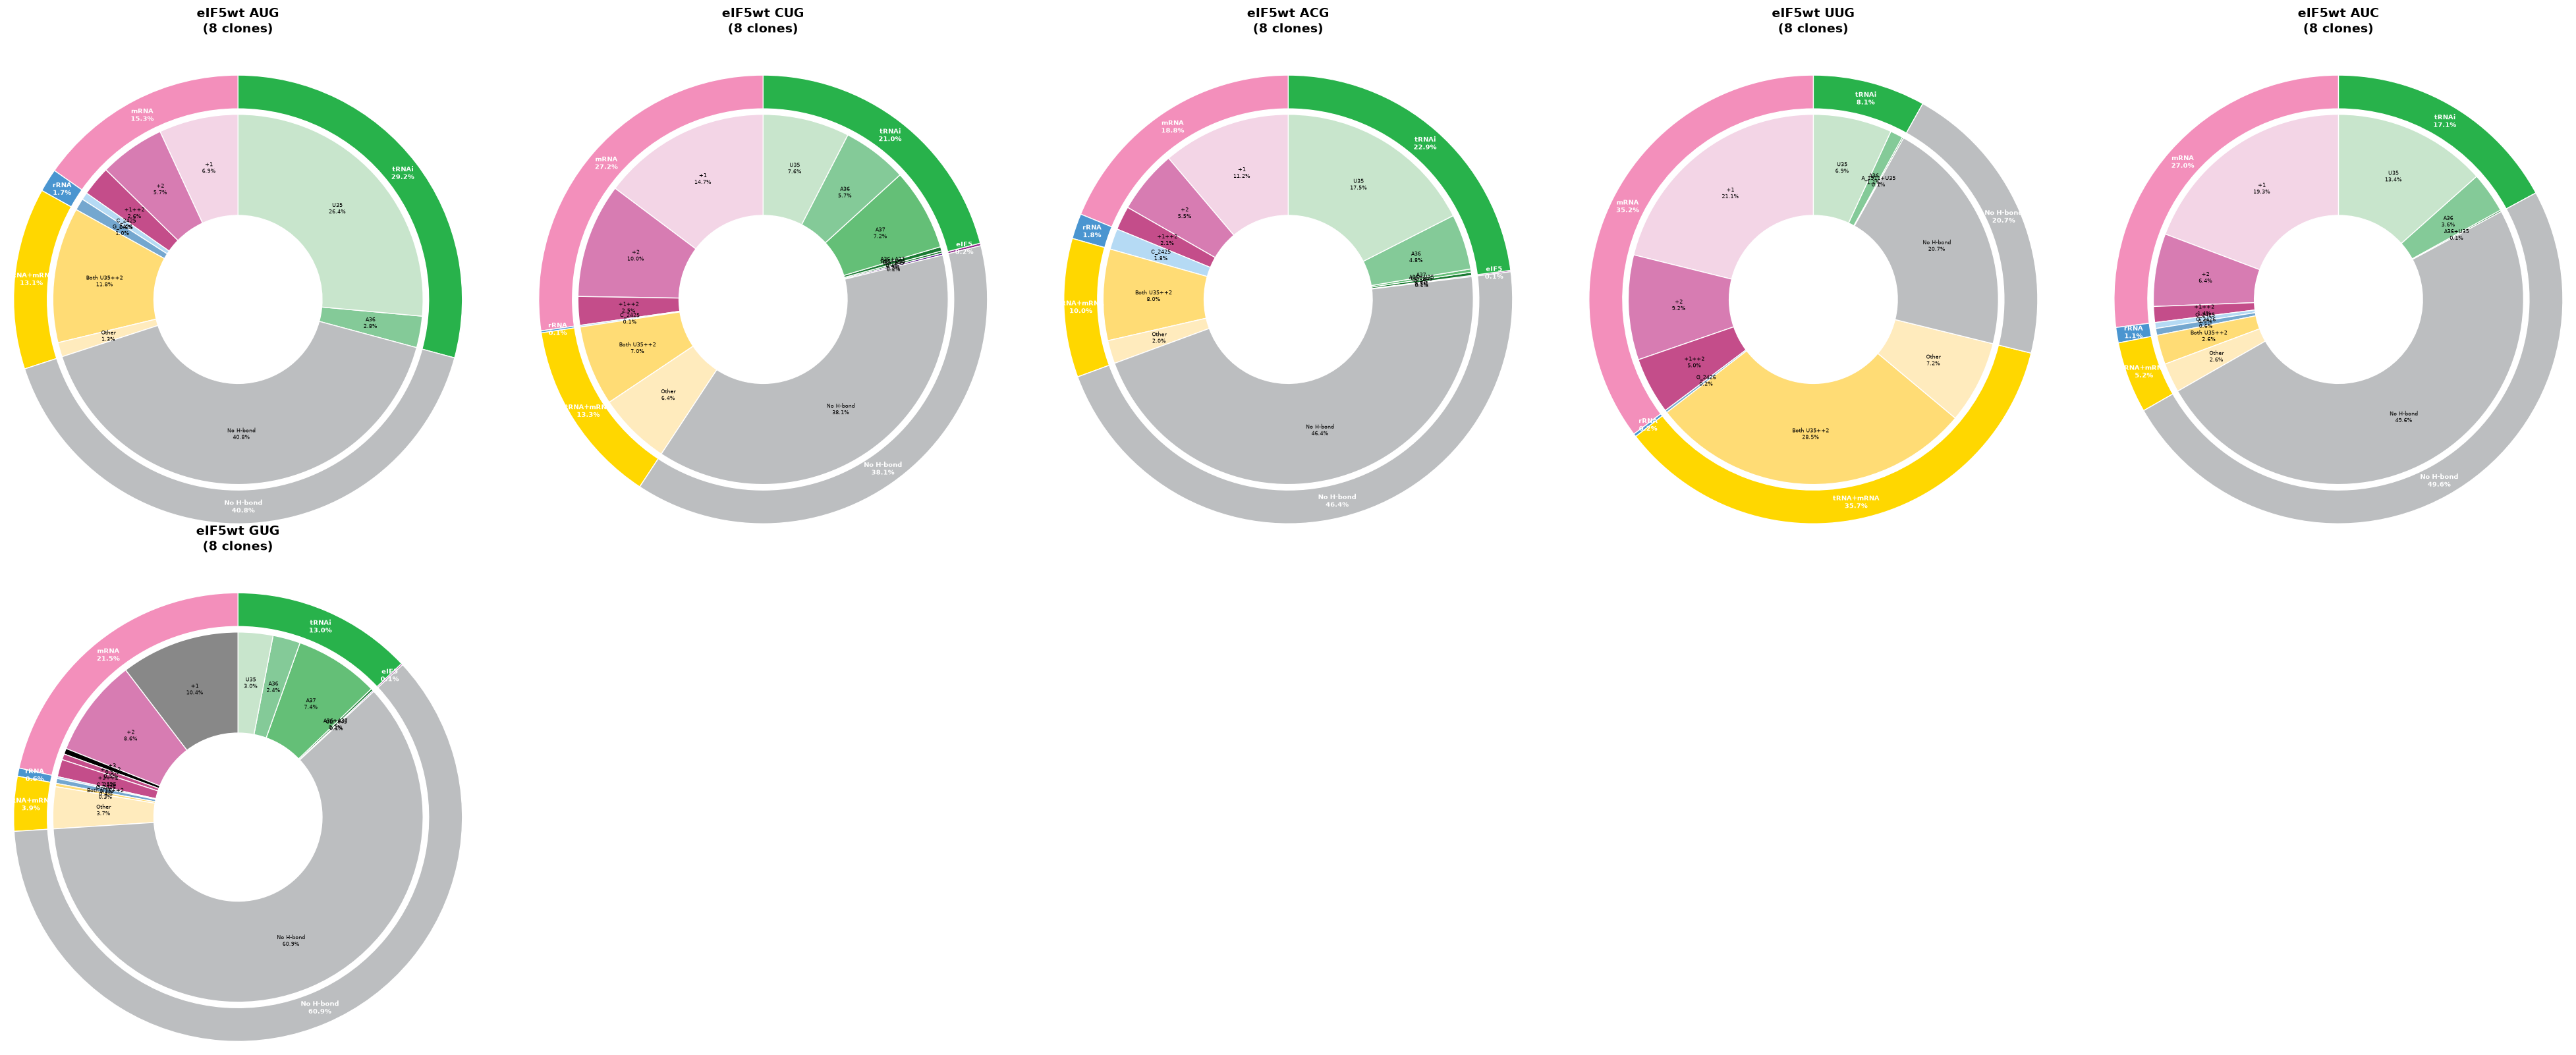

In [15]:
order_start_sites = ['20251112_eIF5wt_AUG', 
                     '20251112_eIF5wt_CUG', 
                     '20251112_eIF5wt_ACG', 
                     '20251112_eIF5wt_UUG', 
                     '20251112_eIF5wt_AUC',
                    '20251112_eIF5wt_GUG']

wildtype_start_sites = {
    k: v for k, v in sorted(
        systems.items(), 
        key=lambda x: order_start_sites.index(x[0]) if x[0] in order_start_sites else float('inf')
    ) if k.startswith('20251112_eIF5wt')
}


n_systems = len(wildtype_start_sites)
n_cols = min(5, n_systems)
n_rows = (n_systems + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(8*n_cols, 8*n_rows),
                         subplot_kw=dict(projection="polar"))
if n_systems == 1:
    axes = np.array([axes])
axes = axes.flatten()

for idx, (system_key, system_files) in enumerate(wildtype_start_sites.items()):
    info = parse_filename(system_files[0].name)
    
    print(f"Processing {system_key} ({len(system_files)} clones)...")
    
    combined_matrix, residue_names, date = aggregate_clones(system_files)
    fractions, bridging_fractions, same_domain_fractions = calculate_hbond_fractions(
        combined_matrix, residue_names, date
    )
    
    title = f"{info['variant']} {info['codon']}\n({len(system_files)} clones)"
    plot_nested_hbond_pie_simple(fractions, date, title, 
                                  bridging_fractions=bridging_fractions,
                                  same_domain_fractions=same_domain_fractions,
                                  codon=info['codon'],
                                  ax=axes[idx])

for idx in range(n_systems, len(axes)):
    axes[idx].set_axis_off()

plt.tight_layout()
plt.savefig(FIG_DIR / "ExtFig5G_N30_partners_wt_codons.png", dpi=150, transparent=True)
plt.show()

## eIF5 variants, AUG

Processing 20251112_eIF5_N30K_AUG (8 clones)...
  Found 11 unique residues across 8 clones


Processing 20251112_eIF5_G29A_G31A_AUG (8 clones)...
  Found 12 unique residues across 8 clones


Processing 20251112_eIF5_N30Q_AUG (8 clones)...
  Found 12 unique residues across 8 clones


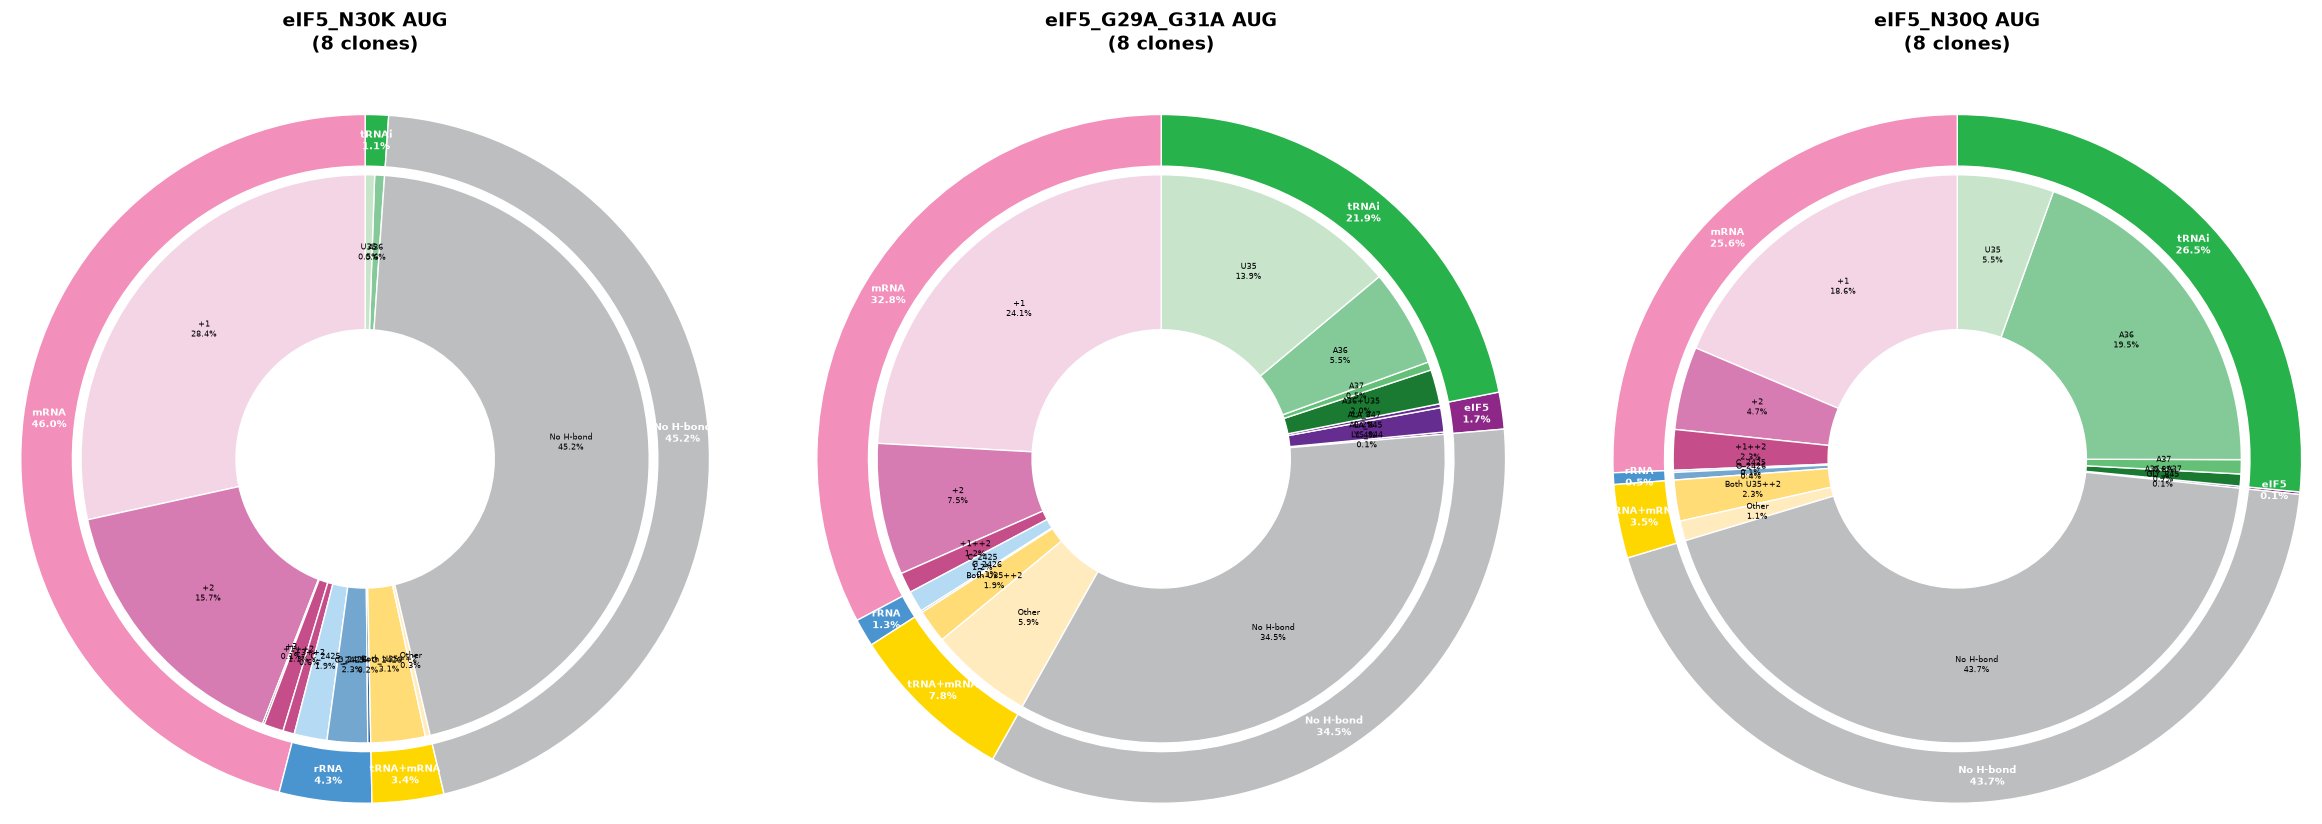

In [16]:
order_start_sites = ['20251112_eIF5_N30K_AUG', 
                     '20251112_eIF5_N30Q_G31A_AUG', 
                     '20251112_eIF5_G29A_G31A_AUG', 
                     ]

mutant_start_sites = {
    k: v for k, v in sorted(
        systems.items(), 
        key=lambda x: order_start_sites.index(x[0]) if x[0] in order_start_sites else float('inf')
    ) if k.startswith('20251112_eIF5_')
}


n_systems = len(mutant_start_sites)
n_cols = min(3, n_systems)
n_rows = (n_systems + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(8*n_cols, 8*n_rows),
                         subplot_kw=dict(projection="polar"))
if n_systems == 1:
    axes = np.array([axes])
axes = axes.flatten()

for idx, (system_key, system_files) in enumerate(mutant_start_sites.items()):
    info = parse_filename(system_files[0].name)
    
    print(f"Processing {system_key} ({len(system_files)} clones)...")
    
    combined_matrix, residue_names, date = aggregate_clones(system_files)
    fractions, bridging_fractions, same_domain_fractions = calculate_hbond_fractions(
        combined_matrix, residue_names, date
    )
    
    title = f"{info['variant']} {info['codon']}\n({len(system_files)} clones)"
    plot_nested_hbond_pie_simple(fractions, date, title, 
                                  bridging_fractions=bridging_fractions,
                                  same_domain_fractions=same_domain_fractions,
                                  codon=info['codon'],
                                  ax=axes[idx])

for idx in range(n_systems, len(axes)):
    axes[idx].set_axis_off()

plt.tight_layout()
plt.savefig(FIG_DIR / "ExtFig5G_N30_partners_eIF5_variants.png", dpi=150, transparent=True)
plt.show()